# Figure 1B: is the increase from 158 to 176 red sites unusual?

This notebook reconstructs the Figure 1B comparisons in
[Karbacher et al.](https://onlinelibrary.wiley.com/doi/10.1002/mco2.70899) and asks:
**If we randomly reassign participants to groups, how often does the same analysis
produce an increase of at least +18 red sites from before to after?**

We keep the measurements fixed, shuffle participants jointly across both visits and
all CpGs, refit the same limma model, and count sites passing the same thresholds.
For each shuffle we calculate **after count − before count**. The primary permutation
p-value tests this increase. Separate tests of each visit's total count follow for context.

**Status: unrestricted diagnostic with unresolved group labels.** The public diet
annotations conflict. Original trial methods also report randomization in blocks of 13,
but the public methylation annotations do not identify block membership. The saved run
uses unrestricted 24/24 shuffles, so it does not reproduce the original blocked allocation.
The groups remain **code 0** and **code 1**, without assigning diet names.

All outputs are saved. **Run All** reloads the saved results; it does not refit thousands
of permutations. The [README](../README.md) documents the full pipeline.

In [1]:
from pathlib import Path
import json
import sys
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

%matplotlib inline

ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data/processed/audit.json").exists()
     and (p / "results/diet_code/permutation_run.json").exists()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the vegandiet project or its notebooks folder.")

OUT = ROOT / "results/diet_code"
audit = json.loads((ROOT / "data/processed/audit.json").read_text())
run = json.loads((OUT / "permutation_run.json").read_text())
summary = pd.read_csv(OUT / "limma_summary.csv").set_index("time")
samples = pd.read_csv(ROOT / "data/processed/samples.csv",
                      dtype={"participant": str, "diet_code": str})

# Fixed rules used for the Figure 1B comparison below.
ALPHA = 0.05
EFFECT_CUTOFF = 0.5
TIMES = ("before", "after")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 14)
display(Markdown(f"Loaded **{audit['matrix_shape'][0]:,} CpGs**, "
                 f"**{audit['participants']} participants**, "
                 f"and a saved run of **{run['repetitions']:,} permutations**."))

Loaded **812,934 CpGs**, **48 participants**, and a saved run of **9,999 permutations**.

## 1. Observed red-site counts

A site is red when it meets **both** original rules: limma raw two-sided $p < 0.05$
and $|\Delta M| > 0.5$. Every shuffled analysis uses these same rules.
These are counts of thresholded CpGs, rather than genome-wide discoveries after
multiple-testing correction. The effect scale and candidate model are explained below.

In [2]:
overview = pd.DataFrame({
    "Paper (reported)": [158, 182],
    "Observed reconstruction": [int(summary.loc[t, "highlighted"]) for t in TIMES],
}, index=["Before", "After"]).T
overview.columns.name = "Red CpGs under the original limma rule"
display(overview)
display(Markdown(
    "The observed reconstruction gives **158 before and 176 after**, compared with "
    "**158 and 182** reported in the paper. The count test below uses the reconstructed "
    "observed counts, so observed and shuffled analyses use the same pipeline. "
    "A matching baseline count does not verify the group assignments or site identities."
))

Red CpGs under the original limma rule,Before,After
Paper (reported),158,182
Observed reconstruction,158,176


The observed reconstruction gives **158 before and 176 after**, compared with **158 and 182** reported in the paper. The count test below uses the reconstructed observed counts, so observed and shuffled analyses use the same pipeline. A matching baseline count does not verify the group assignments or site identities.

## 2. Test the change: after minus before

At each visit $v$, count sites passing the original red-site rule:

$$C_v = \sum_{j=1}^{812934} \mathbf{1}\{p^{\mathrm{limma}}_{j,v}<0.05
\;\mathrm{and}\;|\Delta M_{j,v}|>0.5\}.$$

Our statistic is the **signed count change**:

$$D = C_{\mathrm{after}}-C_{\mathrm{before}},\qquad D_{\mathrm{observed}}=176-158=18.$$

The saved simulation already performed the expensive fitting steps **9,999 times**:

1. Keep all methylation measurements fixed.
2. Randomly reassign the 48 participants to two groups of 24.
3. Apply the **same assignment to both visits and every CpG**. Each person's before/after
   pair stays together, and the relationships between CpGs are preserved.
4. Refit the same four group-by-visit means and re-estimate limma's empirical Bayes
   variance prior. Apply exactly the same raw-p and effect thresholds.
5. Record the before and after red-site counts for that assignment.

We now subtract those counts **within each saved row** to obtain $D_b$. No new model
fits are needed. We do not independently shuffle visits or mix counts from different
assignments. To ask whether the observed **increase** is unusually large, use

$$p_{\mathrm{increase}}
=\frac{1+\#\{D_b\ge18\}}{9999+1}.$$

This is a **one-sided upper-tail test**, including ties. The added 1 accounts for the
observed assignment in the Monte Carlo calculation. The site-level limma p-values
inside the red-site rule remain two-sided. This answers the question about an increase;
testing unusually large changes in either direction would require a two-sided statistic.

The histogram shows all 9,999 changes. The red line marks +18; dark bars show increases
of +18 or more. Each shuffle uses its **own baseline count**, so this is not conditional
on starting at exactly 158 and is not the probability of the exact pair 158 → 176.
The middle 95% range describes shuffled changes, not a confidence interval for a diet effect.

**Allocation assumption:** these are unrestricted fixed-size shuffles.
[Original trial methods](https://doi.org/10.3390/microorganisms9040727) report block
randomization (block size 13). Verified diet assignments, participant-to-block mapping
and the allocation procedure for the methylation subset are unavailable. Thus the
present calculation is conditional on joint exchangeability of whole participant
profiles, not an exact randomization test under the documented trial design. Blocks
cannot be recovered just by splitting sorted participant IDs into groups of 13.
The relevance of exchangeability restrictions is discussed in the
[permutation inference reference](https://pmc.ncbi.nlm.nih.gov/articles/PMC4010955/).

,Observed change,Shuffle median change,Shuffled 2.5%,Shuffled 97.5%,Shuffles ≥ observed change,Total shuffles,Increase p (upper tail),Monte Carlo SE
After − before,+18,+2,-88,+94,2629,9999,0.2630,0.0044


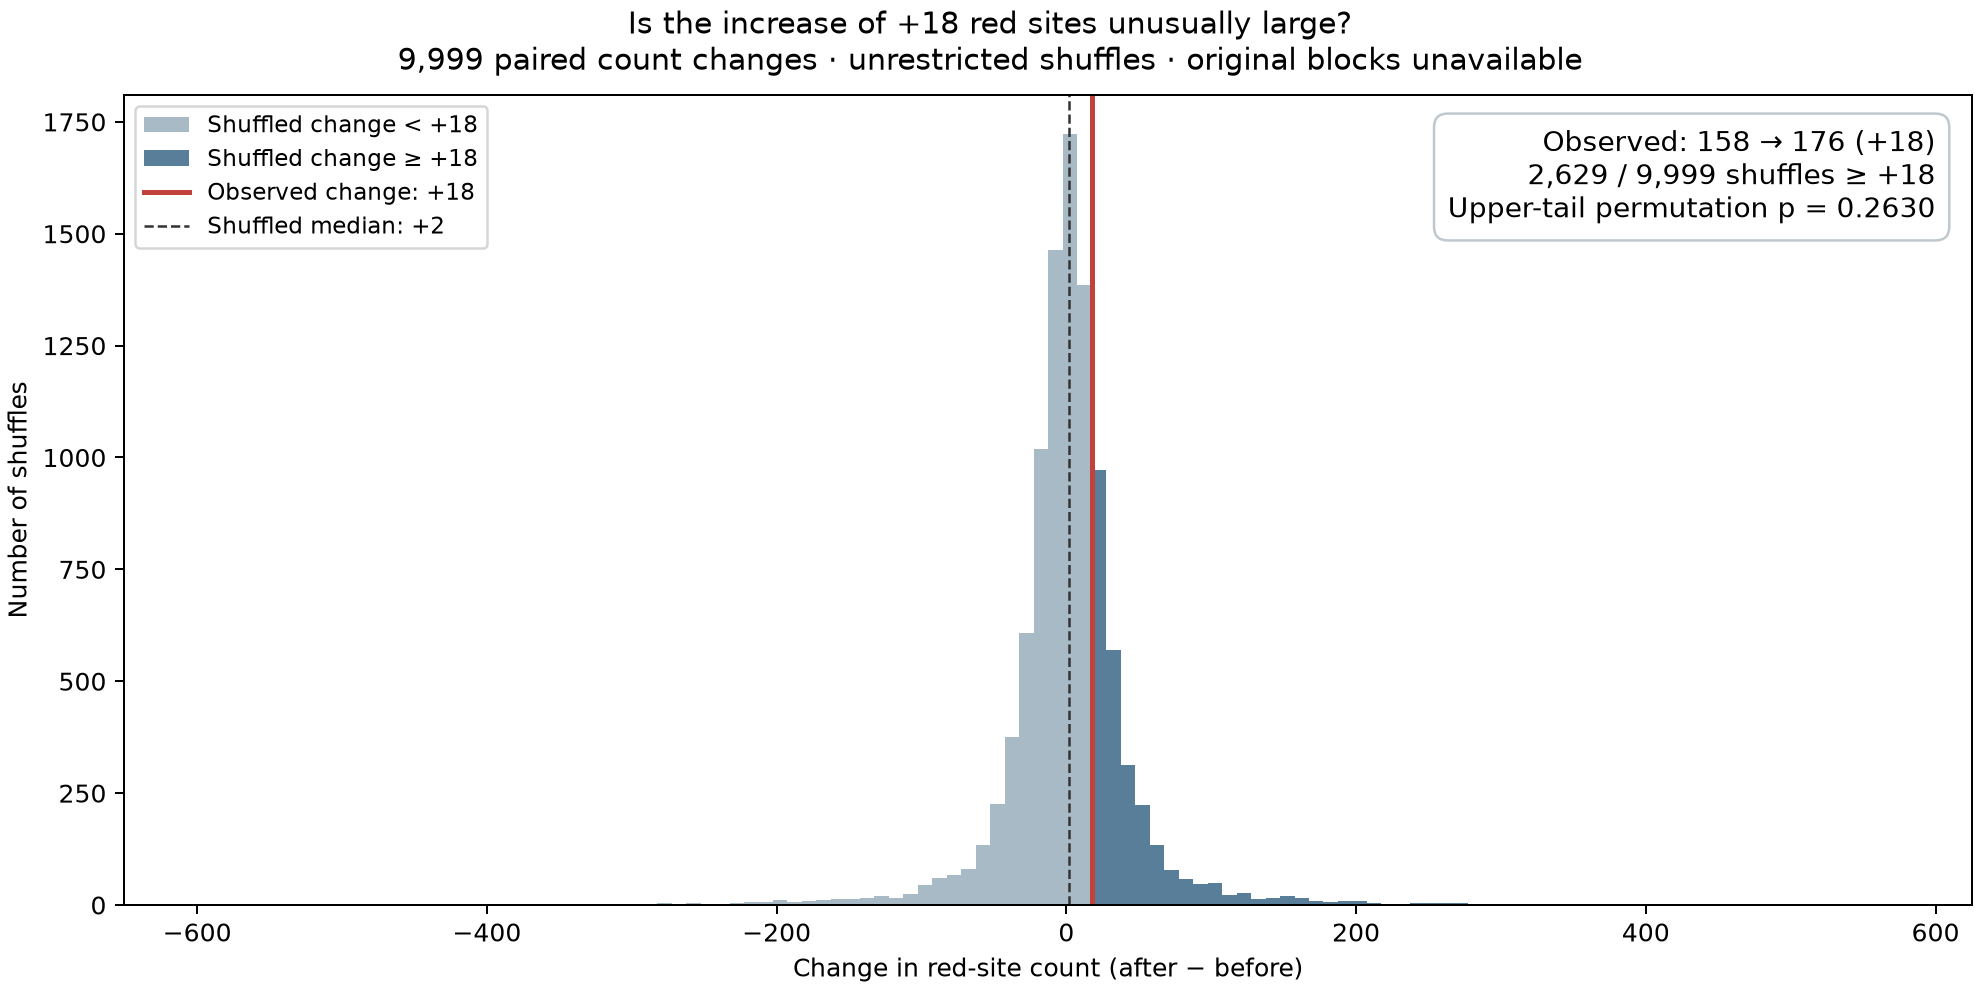

**Result:** 2,629 of 9,999 shuffles gave an increase of **+18 or more**. With the +1 correction, **p = (2,629 + 1) / (9,999 + 1) = 0.2630**. An increase this large occurs in about **26.3%** of assignments under this unrestricted scheme, so the observed increase is not unusual. This is not the probability that there is no diet effect.

**First five paired changes:** each row is one shared participant assignment.

,before,after,change
shuffle,,,
1,381,340,-41
2,196,196,0
3,305,278,-27
4,163,189,26
5,170,178,8


In [3]:
null_counts = pd.read_csv(OUT / "permutation_null_counts.csv")
B = len(null_counts)
assert B == run["repetitions"]
# Subtract within each assignment: before and after share the same participant grouping.
changes = null_counts["after"] - null_counts["before"]
observed_change = int(summary.loc["after", "highlighted"] - summary.loc["before", "highlighted"])
extreme_changes = int((changes >= observed_change).sum())
change_p = (1 + extreme_changes) / (B + 1)

# Independently check the saved summary and paired export before displaying them.
saved_changes = pd.read_csv(OUT / "permutation_null_changes.csv")
np.testing.assert_array_equal(saved_changes["shuffle"], np.arange(1, B+1))
np.testing.assert_array_equal(saved_changes[["before", "after"]], null_counts[["before", "after"]])
np.testing.assert_array_equal(saved_changes["change"], changes)
saved_change_test = pd.read_csv(OUT / "change_test_summary.csv").iloc[0]
assert observed_change == saved_change_test.observed_change
assert extreme_changes == saved_change_test.shuffles_ge_observed
assert np.isclose(change_p, saved_change_test.change_p_upper)

change_results = pd.DataFrame([{
    "Observed change": observed_change,
    "Shuffle median change": changes.median(),
    "Shuffled 2.5%": changes.quantile(0.025),
    "Shuffled 97.5%": changes.quantile(0.975),
    "Shuffles ≥ observed change": extreme_changes,
    "Total shuffles": B,
    "Increase p (upper tail)": change_p,
    "Monte Carlo SE": np.sqrt(change_p * (1-change_p) / B),
}], index=["After − before"])
display(change_results.style.format({
    "Observed change": "{:+.0f}", "Shuffle median change": "{:+.0f}",
    "Shuffled 2.5%": "{:+.0f}", "Shuffled 97.5%": "{:+.0f}",
    "Increase p (upper tail)": "{:.4f}", "Monte Carlo SE": "{:.4f}",
}))
display(Image(filename=str(OUT / "null_changes.png"), width=1100))
display(Markdown(
    f"**Result:** {extreme_changes:,} of {B:,} shuffles gave an increase of "
    f"**{observed_change:+d} or more**. With the +1 correction, "
    f"**p = ({extreme_changes:,} + 1) / ({B:,} + 1) = {change_p:.4f}**. "
    f"An increase this large occurs in about **{100*change_p:.1f}%** of assignments "
    "under this unrestricted scheme, so the observed increase is not unusual. "
    "This is not the probability that there is no diet effect."
))
display(Markdown("**First five paired changes:** each row is one shared participant assignment."))
display(saved_changes.head().set_index("shuffle"))

## 3. Separate count tests at each visit

For context, we can ask whether the observed **total** count at either visit is unusually
large. These are secondary diagnostics, distinct from the change test above.
Using the same 9,999 assignments, compare each visit's count with its observed count:

$$p_{\mathrm{count},v}
=\frac{1+\#\{C_{v,b}\ge C_{v,\mathrm{observed}}\}}{9999+1}.$$

The site-level limma test remains two-sided; these **count tests are upper-tailed**.
They ask about an excess of red sites. The two visit-specific p-values are shown
separately, without an across-visit adjustment.

The histograms show shuffled counts with a red line at each observed count. Dark bars
are the upper tails used for the p-values. Their middle 95% ranges describe shuffled
counts, not confidence intervals for diet effects. A few paired counts are also shown.

,Observed red sites,Shuffle median,Shuffled 2.5%,Shuffled 97.5%,Shuffles ≥ observed,Count p (upper tail),Monte Carlo SE
Visit,,,,,,,
Before,158,200,147.0,437.0,9334,0.9335,0.0025
After,176,203,151.0,438.1,8072,0.8073,0.0039


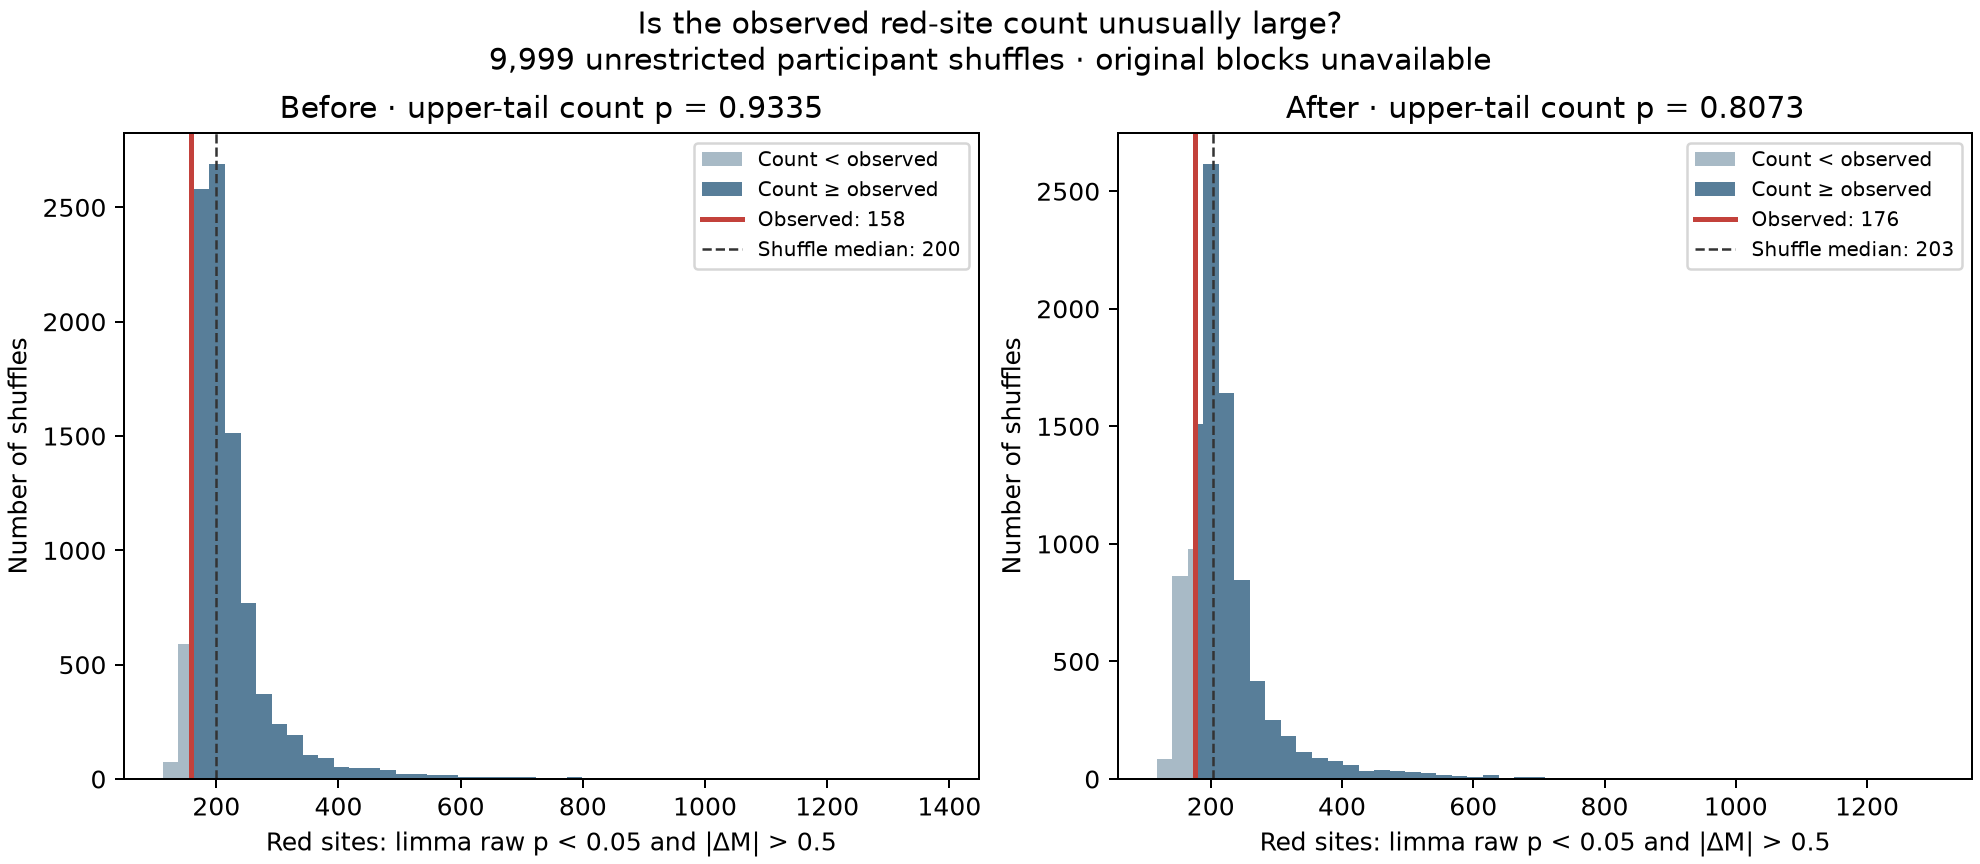

**Interpretation:** the upper-tail p-values are **0.9335 before** and **0.8073 after**. The observed red-site counts are not unusually large under these unrestricted shuffles. This does not prove that the diet has no effect.

**First five sampled assignments:** each row used one common grouping for both visits and every CpG.

,Before red sites,After red sites
Shuffle,,
1,381,340
2,196,196
3,305,278
4,163,189
5,170,178


In [4]:
null_counts = pd.read_csv(OUT / "permutation_null_counts.csv")
B = len(null_counts)
assert B == run["repetitions"]
saved_count_test = pd.read_csv(OUT / "count_test_summary.csv").set_index("time")
count_rows = []
for time in TIMES:
    observed_count = int(summary.loc[time, "highlighted"])
    # Keep limma p-values inside the red-site rule. Only the total count is tested here.
    extreme = int((null_counts[time] >= observed_count).sum())
    count_p = (1 + extreme) / (B + 1)
    assert extreme == saved_count_test.loc[time, "shuffles_ge_observed"]
    assert np.isclose(count_p, saved_count_test.loc[time, "count_p_upper"])
    count_rows.append({
        "Visit": time.title(),
        "Observed red sites": observed_count,
        "Shuffle median": int(null_counts[time].median()),
        "Shuffled 2.5%": null_counts[time].quantile(0.025),
        "Shuffled 97.5%": null_counts[time].quantile(0.975),
        "Shuffles ≥ observed": extreme,
        "Count p (upper tail)": count_p,
        "Monte Carlo SE": np.sqrt(count_p * (1 - count_p) / B),
    })
count_results = pd.DataFrame(count_rows).set_index("Visit")
display(count_results.style.format({
    "Shuffled 2.5%": "{:.1f}", "Shuffled 97.5%": "{:.1f}",
    "Count p (upper tail)": "{:.4f}", "Monte Carlo SE": "{:.4f}",
}))
display(Image(filename=str(OUT / "null_counts.png"), width=1100))
display(Markdown(
    f"**Interpretation:** the upper-tail p-values are "
    f"**{count_results.loc['Before', 'Count p (upper tail)']:.4f} before** and "
    f"**{count_results.loc['After', 'Count p (upper tail)']:.4f} after**. "
    "The observed red-site counts are not unusually large under these unrestricted "
    "shuffles. This does not prove that the diet has no effect."
))
first_shuffles = null_counts.head(5).copy()
first_shuffles.index = pd.RangeIndex(1, len(first_shuffles) + 1, name="Shuffle")
display(Markdown("**First five sampled assignments:** each row used one common grouping for both visits and every CpG."))
display(first_shuffles.rename(columns={"before": "Before red sites", "after": "After red sites"}))

## 4. Why the group labels remain unresolved

The deposited sample annotations contain a numeric diet field and a named diet field.
They do not identify the same grouping. The cross-tabulation below counts **participants**
using their baseline record, so people are not counted twice.

The numeric groups each contain 24 participants. The named groups contain 26 vegan and
22 meat-rich participants. Both fields stay constant within a person's two visits.
Neither numeric code can be translated into a diet name from this cross-tabulation.
The numeric grouping is a candidate analysis, not a verified correction of the labels.

In [5]:
assert samples.groupby("participant").size().eq(2).all()
assert samples.groupby("participant")["time"].apply(lambda x: set(x) == {0, 1}).all()
assert samples.groupby("participant")[["diet_code", "diet_named"]].nunique().eq(1).all().all()
baseline = samples.loc[samples.time == 0]
display(pd.crosstab(baseline.diet_code, baseline.diet_named, margins=True,
                    margins_name="Total"))
display(Markdown(
    "Positive fitted effects below mean **code 0 has higher mean M-values than code 1**. "
    "They cannot currently be described as a vegan-versus-meat direction."
))

diet_named,Meat-rich Diet,Vegan Diet,Total
diet_code,,,
0,13,11,24
1,9,15,24
Total,22,26,48


Positive fitted effects below mean **code 0 has higher mean M-values than code 1**. They cannot currently be described as a vegan-versus-meat direction.

## 5. What “fold change” means in this reconstruction

A beta value $β$ describes methylation on a scale from 0 to 1. Our candidate model uses
the transformed value

$$M=\log_2\!\left(\frac{\beta}{1-\beta}\right), \qquad
\Delta M=\overline M_{\mathrm{code\ 0}}-\overline M_{\mathrm{code\ 1}}.$$

The saved limma column `logFC` contains $\Delta M$. Consequently, $2^{\Delta M}$ is the
ratio of **geometric mean methylation odds** between the two groups. An effect of 0.5
corresponds to an odds ratio of $\sqrt{2}\approx1.414$. It is not a 50-percentage-point
change, nor a ratio of arithmetic mean beta values. The use of M-values is an explicit
reconstruction assumption; the figure label alone does not establish the authors' input scale.

We fit four group-by-time means and test code 0 minus code 1 at each visit.
The candidate model has 92 residual degrees of freedom and no participant blocking.
limma **moderates** the site variances by borrowing information across CpGs, making
individual variance estimates less unstable. Its parametric p-values then use a
moderated t reference distribution. This is not the ordinary Welch t-test.

The two visits are correlated within a person. The original candidate limma model does
not explicitly model that correlation; the participant shuffles preserve the pairs.
Both visit-specific contrasts are between-group comparisons. They do not directly test
whether the two groups *changed differently* from baseline.

## 6. Volcano plots: observed groups and one shuffled grouping

Each point is one CpG. The horizontal coordinate is the fitted mean M-value difference;
the vertical coordinate is $-\log_{10}(p^{\mathrm{limma}})$. Dashed lines show the same
thresholds in all four panels, and red points meet both.

- **Top row:** the observed grouping, giving 158 red sites before and 176 after.
- **Bottom row:** one participant reassignment from the example seed shown below.
  The same reassignment is applied to both visits and every CpG. The same R/limma
  script refits the model and variance moderation.

Both fitted effects and limma p-values change when the groups are reassigned. The
example is the first assignment generated by its specified seed, chosen before
fitting. Its saved p-values and fitted effects are checked against the red-site counts.
The example seed can be changed independently of the full count-test seed.

The p-values on the vertical axes are the limma p-values fitted within each displayed
grouping. The bottom row provides a visual sanity check. The change-test histogram in section 2 uses all 9,999 assignments to assess the
increase of +18. The separate visit-specific count diagnostics are in section 3.

**Displayed example: seed 70900**, 227 red sites before and 202 after. The full change and count tests in sections 2–3 use seed 70899.

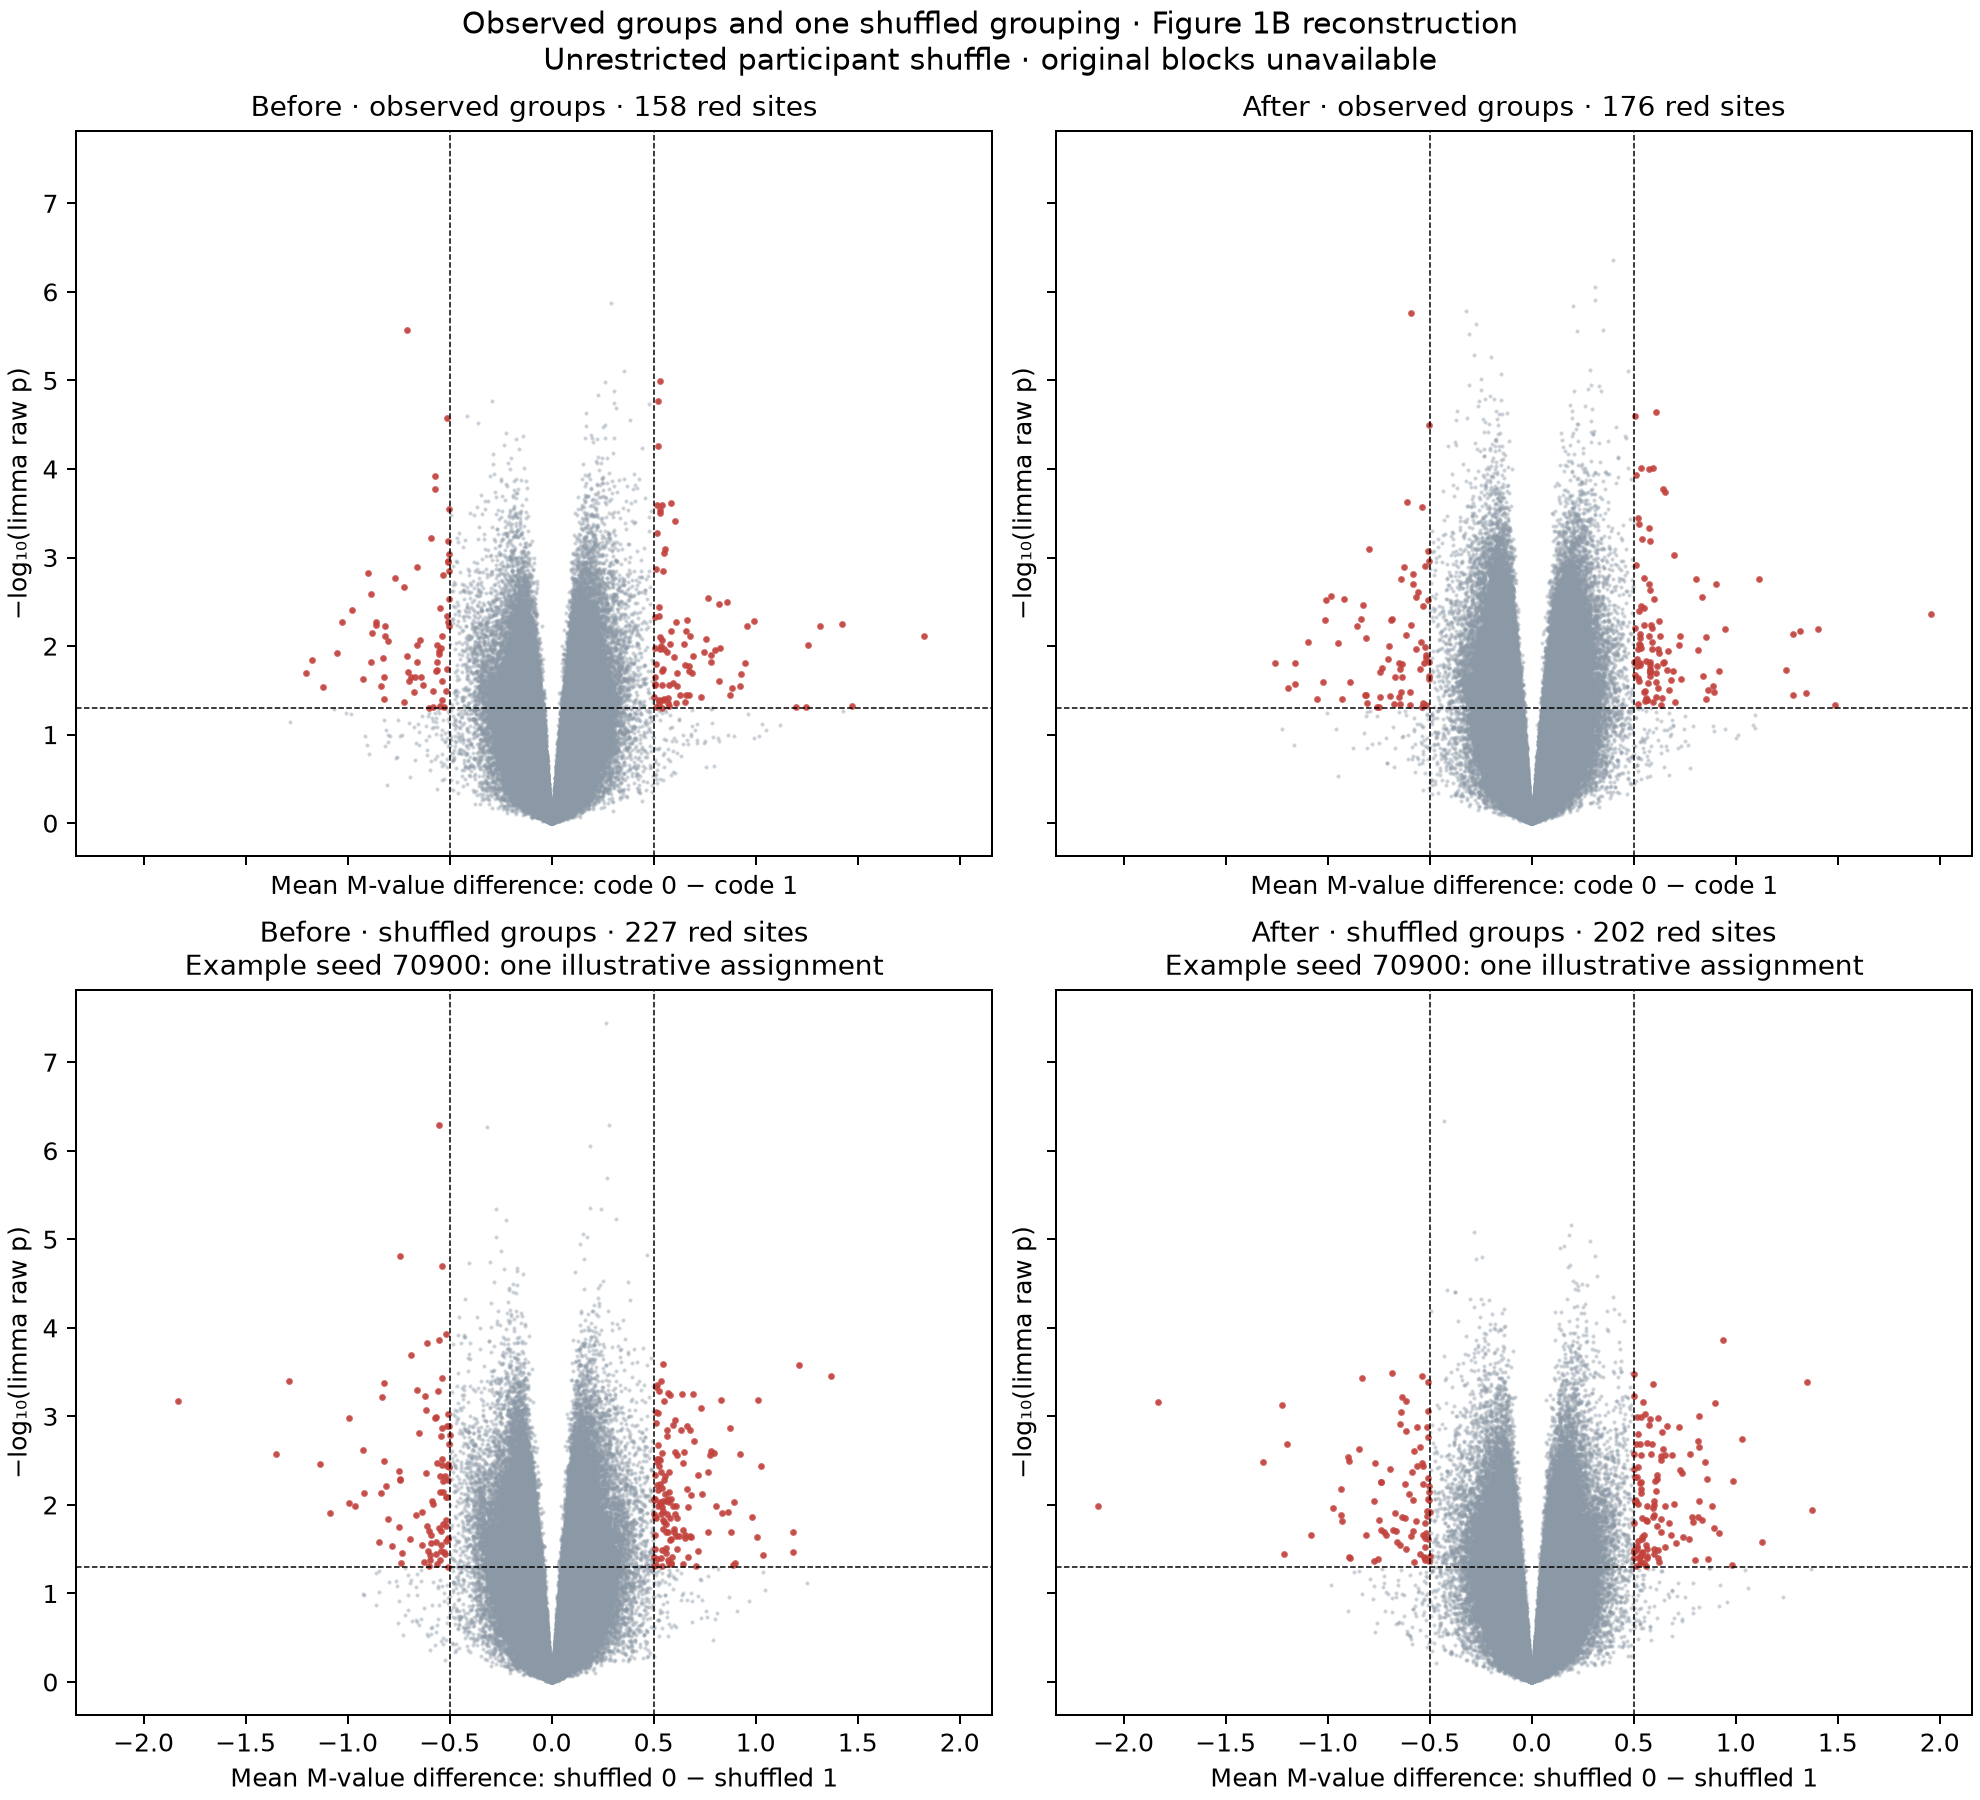

In [6]:
example_run = json.loads((OUT / "shuffled_example/run.json").read_text())
example_counts = example_run["observed_counts_in_this_shuffle"]
display(Markdown(
    f"**Displayed example: seed {example_run['seed']}**, "
    f"{example_counts['before']} red sites before and {example_counts['after']} after. "
    f"The full change and count tests in sections 2–3 use seed {run['seed']}."
))
display(Image(filename=str(OUT / "figure1b_observed_and_shuffled.png"), width=1050))

## 7. What the change test establishes

The reconstructed increase is **176 − 158 = +18** red sites. Of 9,999 joint participant
shuffles, **2,629 give an increase of at least +18**, yielding an upper-tail permutation
p-value of **0.2630** with the +1 correction. Thus an increase this large is fairly
common under the specified numeric-code model and unrestricted shuffling scheme.
The separate visit-specific counts are also not unusually large.

The change test compares paired counts from the same assignment. It preserves the
relationships between visits and between CpGs without assuming that the 812,934 site
tests are independent. A net increase of 18 does not mean exactly 18 sites became red:
some sites can enter and others leave the red set. This statistic does not identify
individual effects or test a diet-by-time interaction at individual CpGs.

The statistic and upper-tail direction were chosen during exploratory review. The
p-value is not the probability that the null hypothesis is true, nor evidence of
equivalent diets or absence of methylation effects. It refers to increases of +18 or
more under the stated scheme, not the probability of exactly the pair 158 → 176.

Exact reproduction of the trial analysis still requires verified diet assignments,
randomization blocks and the authors' Figure 1B script. The after count differs from
the paper by six. The empirical Bayes calculation and each shuffled red count have
been independently checked against R limma for every assignment in a small example;
all observed site statistics were checked against R before the full saved run.

## 8. Sensitivity to the annotation field and model design

These rows use either the numeric field or the conflicting named field. They also compare
the four-cell model, which pools residual variance across visits, with a separate fit at each
visit. They are recorded alternatives, not settings tuned to recover the published count.
The later subject-blocked model mentioned in the paper is not reconstructed here.

The named-label scenario uses different participant assignments and unequal group sizes.
Any BH findings in that scenario cannot validate a vegan-versus-meat effect while the
annotations remain unresolved.

In [7]:
sensitivity = []
for field, label in [("diet_code", "Numeric codes (24 / 24)"),
                     ("diet_named", "Named diets (26 / 22)")]:
    folder = ROOT / "results" / field
    pooled = pd.read_csv(folder / "limma_summary.csv").set_index("time")
    separate = pd.read_csv(folder / "separate_time_sensitivity.csv").set_index("time")
    for model, table, indices in [("Four cell means", pooled, TIMES),
                                  ("Separate visits", separate, (0, 1))]:
        sensitivity.append({"Annotation": label, "Model": model,
            "Before highlighted": int(table.loc[indices[0], "highlighted"]),
            "After highlighted": int(table.loc[indices[1], "highlighted"]),
            "Before BH < 0.05": int(table.loc[indices[0], "bh_below_005"]),
            "After BH < 0.05": int(table.loc[indices[1], "bh_below_005"])})
display(pd.DataFrame(sensitivity).set_index(["Annotation", "Model"]))

Before highlighted  \
Annotation              Model                                 
Numeric codes (24 / 24) Four cell means                 158   
                        Separate visits                 160   
Named diets (26 / 22)   Four cell means                 668   
                        Separate visits                 665   

                                         After highlighted  Before BH < 0.05  \
Annotation              Model                                                  
Numeric codes (24 / 24) Four cell means                176                 0   
                        Separate visits                177                 0   
Named diets (26 / 22)   Four cell means                502                 1   
                        Separate visits                506                 0   

                                         After BH < 0.05  
Annotation              Model                             
Numeric codes (24 / 24) Four cell means                0  
                        Separate visits                0  
Named diets (26 / 22)   Four cell means                1  
                        Separate visits                0

## 9. Inspect an individual CpG from the limma analysis

This optional example shows the measurements behind one point in the observed volcano
plots. Set `SITE` below to a CpG ID and rerun the example. With `SITE = None`, we select
the red follow-up site with the smallest limma p-value. This is a descriptive selection
after inspecting the results, not independent confirmation of an effect.

The table shows the fitted M-value difference, original raw limma p-value, and its
Benjamini–Hochberg (BH) adjustment over all CpGs at that visit. No site in the numeric
grouping has a BH-adjusted p-value below 0.05. Red sites follow the figure's raw-p and
effect rule; they are not genome-wide discoveries after multiple-testing correction.

The plots show each participant's measured beta values and group means. Each person
appears in both panels. These beta means are descriptive; the fitted effect uses M-values.

In [8]:
columns = ["cpg", "logFC", "t", "P.Value", "adj.P.Val"]
results = {
    time: pd.read_csv(OUT / f"{time}_limma.csv.gz", usecols=columns).set_index("cpg")
    for time in TIMES
}
for time, table in results.items():
    assert len(table) == audit["matrix_shape"][0] and table.index.is_unique
    assert np.isfinite(table.to_numpy()).all()
    for pcol in ("P.Value", "adj.P.Val"):
        assert table[pcol].between(0, 1).all()
    table["highlighted"] = (table.logFC.abs() > EFFECT_CUTOFF) & (table["P.Value"] < ALPHA)
    assert int(table.highlighted.sum()) == summary.loc[time, "highlighted"]

**Selected CpG: `cg02717117`**

,ΔM (0 − 1),limma raw p,limma BH-adjusted p,Red under original rule
Before,-0.513781,0.000027,0.999994,True
After,-0.593588,0.000002,0.234,True


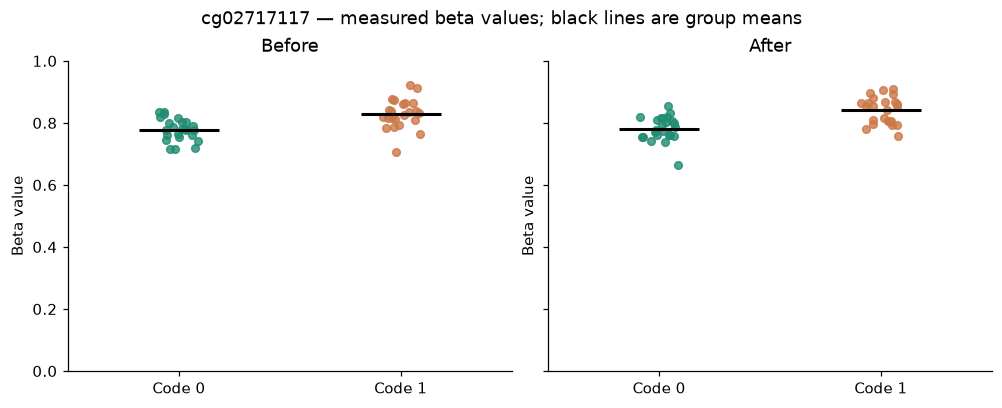

In [9]:
SITE = None  # Replace with an ID such as "cg14817997" to inspect another site.
if SITE is None:
    candidates = results["after"].loc[results["after"].highlighted, "P.Value"]
    SITE = candidates.idxmin() if len(candidates) else results["after"]["P.Value"].idxmin()
if not all(SITE in table.index for table in results.values()):
    raise KeyError(f"CpG {SITE!r} is absent from the result tables")

display(Markdown(f"**Selected CpG: `{SITE}`**"))
site_table = pd.DataFrame({time.title(): table.loc[SITE, [
    "logFC", "P.Value", "adj.P.Val", "highlighted"
]] for time, table in results.items()}).T.rename(columns={
    "logFC": "ΔM (0 − 1)", "P.Value": "limma raw p", "adj.P.Val": "limma BH-adjusted p",
    "highlighted": "Red under original rule",
})
display(site_table)

beta_path = ROOT / "data/processed/beta.bin"
if beta_path.exists():
    shape = tuple(audit["matrix_shape"])
    assert beta_path.stat().st_size == np.prod(shape) * 8
    # Check the explicit CpG ordering before looking up any beta values.
    cpg_ids = pd.Index((ROOT / "data/processed/cpg_ids.txt").read_text().splitlines())
    assert cpg_ids.equals(results["before"].index) and cpg_ids.equals(results["after"].index)
    row = cpg_ids.get_loc(SITE)
    beta = np.memmap(beta_path, dtype="<f8", mode="r", shape=shape)
    observed = samples.copy()
    observed["beta"] = np.array(beta[row])
    del beta
    jitter_rng = np.random.default_rng(70899)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True, layout="constrained")
    for time, ax in enumerate(axes):
        for x, (group, color) in enumerate((("0", "#208c72"), ("1", "#cc7847"))):
            values = observed.loc[(observed.time == time) & (observed.diet_code == group), "beta"]
            ax.scatter(x + jitter_rng.uniform(-0.09, 0.09, len(values)), values,
                       color=color, s=25, alpha=0.8)
            ax.hlines(values.mean(), x-0.18, x+0.18, color="black", lw=2)
        ax.set(xticks=[0, 1], xticklabels=["Code 0", "Code 1"],
               xlim=(-0.5, 1.5), ylim=(0, 1), title=TIMES[time].title(), ylabel="Beta value")
    fig.suptitle(f"{SITE} — measured beta values; black lines are group means")
    plt.show()
else:
    display(Markdown("The prepared beta matrix is unavailable. The saved per-site test results above remain viewable; run `make prepare` to enable the participant plots."))

## Provenance

In [10]:
provenance = pd.Series({
    "Study accession": "E-MTAB-17025",
    "Sites × samples": f"{audit['matrix_shape'][0]:,} × {audit['matrix_shape'][1]}",
    "Contrast": f"code {run['numerator']} minus code {run['denominator']}",
    "Permutations / seed": f"{run['repetitions']:,} / {run['seed']}",
    "Permutation unit": run["permutation_unit"],
    "Primary statistic": "After red-site count minus before red-site count",
    "Red-site rule": "limma raw p < 0.05 and abs(ΔM) > 0.5",
    "Change/count p-value tails": "Upper, including ties; (1 + extreme) / (B + 1)",
    "Original randomization": "Blocks of 13 reported; participant block membership unavailable",
    "Saved allocation scheme": "Unrestricted 24/24 participant shuffles",
    "Model": run["model"],
    "Variance prior": run["variance_prior"],
    "limma / R used for saved fit": "3.54.0 / 4.3.3 (paper reports R 4.2.3)",
    "Notebook Python": sys.version.split()[0],
    "Notebook libraries": "; ".join(f"{name} {version(name)}" for name in ["numpy", "pandas", "scipy", "matplotlib"]),
    "Source matrix SHA-256": audit["matrix_sha256"],
}, name="Value")
display(provenance.to_frame())

,Value
Study accession,E-MTAB-17025
Sites × samples,"812,934 × 96"
Contrast,code 0 minus code 1
Permutations / seed,"9,999 / 70899"
Permutation unit,participant; one assignment shared by both vis...
Primary statistic,After red-site count minus before red-site count
Red-site rule,limma raw p < 0.05 and abs(ΔM) > 0.5
Change/count p-value tails,"Upper, including ties; (1 + extreme) / (B + 1)"
Original randomization,Blocks of 13 reported; participant block membe...
Saved allocation scheme,Unrestricted 24/24 participant shuffles


## Rerun, explore, and trace the sources

- **Explore:** change `SITE` in section 9, or filter the `results["before"]` and
  `results["after"]` DataFrames. These tables contain every tested CpG.
- **Recompute the change test from saved shuffles:** run `make change-test` (fast; no new shuffles).
- **Recompute the separate count tests from saved shuffles:** run `make count-test` (fast; no new shuffles).
- **Choose a new example seed:** run `make plots EXAMPLE_SEED=70900`, then `make execute-notebook`. With no seed option, later plot builds reuse the last selected seed.
- **Refresh this notebook and its HTML copy:** run `make execute-notebook` from the project root.
- **Repeat the statistical analysis:** use the commands in the [README](../README.md),
  including `make permutation PERMUTATIONS=9999 SEED=70899`. This can take several minutes
  and replaces generated outputs. Then run `make plots` and `make execute-notebook`.
- **Read the implementation:** [limma model](../scripts/figure1b_limma.R),
  [joint shuffles](../scripts/permutation.py), [single-shuffle example](../scripts/shuffled_example.py), [count test](../scripts/count_test.py), [change test](../scripts/change_test.py), and
  [numerical checks](../tests/test_statistics.py).

Primary sources: [paper](https://onlinelibrary.wiley.com/doi/10.1002/mco2.70899),
[public dataset](https://www.ebi.ac.uk/biostudies/arrayexpress/studies/E-MTAB-17025),
[limma guide](https://bioconductor.org/packages/release/bioc/vignettes/limma/inst/doc/usersguide.pdf),
[minfi reference](https://bioconductor.org/packages/release/bioc/manuals/minfi/man/minfi.pdf),
[Monte Carlo permutation p-values](https://arxiv.org/abs/1603.05766),
[permutation inference and exchangeability](https://pmc.ncbi.nlm.nih.gov/articles/PMC4010955/),
and [original trial allocation methods](https://doi.org/10.3390/microorganisms9040727).